# 3章 LLMベースアプリケーション向け評価ツール - 3-1. LamgSmith

## 事前準備

当サンプルコードを実行するには、OpenAIとLangSmithのAPIキーが必要です。

### OpenAI
- OpenAIのプラットフォーム（ https://platform.openai.com/ ）にアクセスし、ご自身のアカウントでログインして、APIキーを生成してください。
- 生成したAPIキーを定数 `OPENAI_API_KEY` に設定します。

```
OPENAI_API_KEY=<作成したAPIキー>
```

### LangSmith

- LangSmithのWebページ（ https://smith.langchain.com/ ）にアクセスし、ご自身のアカウントでログインして、APIキーを生成してください。
   - 参考（ https://docs.langchain.com/langsmith/create-account-api-key ）
- 生成したAPIキーを定数 `LANGSMITH_API_KEY` に設定します。

```
LANGSMITH_API_KEY=<作成したAPIキー>
```


In [ ]:
OPENAI_API_KEY="<作成したAPIキー>"
LANGSMITH_API_KEY="<作成したAPIキー>"
LANGCHAIN_TRACING_V2="true"

In [ ]:
import os
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY
os.environ["LANGSMITH_API_KEY"] = LANGSMITH_API_KEY
os.environ["LANGCHAIN_TRACING_V2"] = LANGCHAIN_TRACING_V2

In [ ]:
!wget "https://drive.google.com/uc?export=download&id=1QQlSIaCDIFql-IHBd9NHd3YiqTAN2gr_" -O apple.txt

--2026-10-22 05:27:55--  https://drive.google.com/uc?export=download&id=1QQlSIaCDIFql-IHBd9NHd3YiqTAN2gr_
Resolving drive.google.com (drive.google.com)... 173.194.69.102, 173.194.69.113, 173.194.69.139, ...
Connecting to drive.google.com (drive.google.com)|173.194.69.102|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1QQlSIaCDIFql-IHBd9NHd3YiqTAN2gr_&export=download [following]
--2026-10-22 05:27:55--  https://drive.usercontent.google.com/download?id=1QQlSIaCDIFql-IHBd9NHd3YiqTAN2gr_&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 192.178.156.132, 2a00:1450:4013:c1c::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|192.178.156.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 410321 (401K) [application/octet-stream]
Saving to: ‘apple.txt’

apple.txt           100%[===================>] 400.70K  --.-KB/s    

In [ ]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.1 MB/s eta 0:00:00


In [ ]:
!pip install rouge_score

  Preparing metadata (setup.py) ... done
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=a1bcccd10fc8b8495dcf085ce512a9d809f782a0c586b79c3d6dd5c6fb421f17
  Stored in directory: /root/.cache/pip/wheels/85/9d/af/01feefbe7d55ef5468796f0c68225b6788e85d9d0a281e7a70
Successfully built rouge_score


In [ ]:
MAX_LENGTH = 20_000
# 10-Kの本文が「apple.txt」というファイルに保存されているものとする
with open('apple.txt', 'r') as file:
    sec_filing = file.read()

sec_filing = sec_filing[:MAX_LENGTH]

In [ ]:
benchmark_summary = """Apple’s fiscal 2024 Form 10-K describes the company as a global provider of iPhone, Mac, iPad, Wearables/Home/Accessories, and Services, managed primarily through geographic segments including the Americas, Europe, Greater China, Japan, and Rest of Asia Pacific. Net sales rose 2% to $391.0 billion in 2024, driven largely by 13% growth in Services, while iPhone sales were roughly flat, Mac sales increased modestly, and iPad and Wearables/Home/Accessories declined. Net income fell to $93.7 billion from $97.0 billion, primarily reflecting a higher effective tax rate caused by a one-time $10.2 billion net income tax charge related to the European Commission State Aid Decision. Apple continued significant capital returns, repurchasing about $95.0 billion of common stock and paying $15.2 billion in dividends and dividend equivalents, while reporting $140.8 billion in unrestricted cash, cash equivalents and marketable securities at year-end. The filing highlights major risks including macroeconomic weakness, foreign currency movements, intense competition, supply-chain concentration, dependence on third-party developers and content, cybersecurity threats, evolving privacy and technology regulation, and significant legal matters such as EU Digital Markets Act investigations, a U.S. Department of Justice antitrust lawsuit, and ongoing App Store-related litigation."""

In [ ]:
import evaluate as hf_evaluate  # Hugging Faceのevaluate
from langsmith import evaluate as langsmith_evaluate  # LangSmithのevaluate
from langsmith import Client
from typing import Dict, Any

ls_client = Client()

In [ ]:
dataset_name = "Golden SEC Summary Dataset"

In [ ]:
# テストケースとなる正解データセットを定義
dataset = ls_client.create_dataset(dataset_name)
ls_client.create_examples(
    inputs=[
        {"sec_filing": sec_filing},
    ],
    outputs=[
        {"summary": benchmark_summary},
    ],
    dataset_id=dataset.id,
)

{'example_ids': ['573f37fb-6d4f-4f5e-95cd-75e6cca8b82b'],
 'count': 1,
 'as_of': '2026-06-11T04:00:31.944886256Z'}

In [ ]:
def calculate_scores(
    outputs: Dict[str, Any],
    reference_outputs: Dict[str, Any]
) -> dict:
    """
    Hugging Faceのevaluateパッケージを使用して、生成された要約と
    参照要約の間のBLEUスコアを計算するカスタム評価関数

    Args:
        outputs (dict): 生成された要約を格納した辞書
        reference_outputs (dict): 参照要約を格納した辞書

    Returns:
        dict: Google BLEUスコアを格納した辞書
    """
    generated = outputs.get("summary", "")
    reference = reference_outputs.get("summary", "")

    # Hugging Faceのevaluateで評価指標を初期化する
    bleu = hf_evaluate.load("google_bleu")

    # BLEU用に入力を整形する
    # （predictionsは文字列のリスト、
    #     referencesは文字列のリストのリストを想定）
    predictions = [generated]
    references = [reference]

    # BLEUスコアを計算する
    bleu_score = bleu.compute(predictions=predictions, references=[references])

    return {"key": "google_bleu", "score": bleu_score["google_bleu"]}

In [ ]:
from openai import OpenAI
oai_client = OpenAI()

TASK = """Generate a summary of approximately five sentences that explains several main points of the following excerpt from an SEC filing."""

PROMPT = f"""
ROLE: You are an expert analyst tasked with summarizing SEC filings.
TASK: {TASK}
"""

xp_model_name = "" # テスト対象のモデル

In [ ]:
def generate_summary(inputs: dict):
    """
    指定されたモデルを使用して、入力の要約を生成する
    """
    response = oai_client.chat.completions.create(
    model=xp_model_name,
        messages=[{"role": "system", "content": PROMPT},
                 {"role": "user", "content": inputs.get("sec_filing")}]
    )
    return {"summary": response.choices[0].message.content}


In [ ]:
def run_evaluation(app, model_name, dataset,  evaluators, upload_results=False):
    global xp_model_name
    xp_model_name = model_name
    results = langsmith_evaluate(
        app,
        client=None,
        data=dataset,
        evaluators=evaluators,
        experiment_prefix=model_name,
        num_repetitions=5,
        # ローカル評価での重要なパラメータ
        upload_results= upload_results
    )

    return results


In [ ]:
app = generate_summary

models = ["gpt-5.4", "gpt-5.4-mini", "gpt-4.1-mini"]

results = [run_evaluation(app, model, dataset=dataset_name,
                          evaluators=[calculate_scores],
                          upload_results=True)
           for model in models]


View the evaluation results for experiment: 'gpt-5.4-ecdc24bb' at:
https://smith.langchain.com/o/9eeb9c6f-c975-4814-8b3e-354fc1f191a6/datasets/a25cf4b8-0828-4401-974d-b10ed070209f/compare?selectedSessions=75735333-c07d-4257-80b3-b45150def5e8




0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


View the evaluation results for experiment: 'gpt-5.4-mini-ed2d8e46' at:
https://smith.langchain.com/o/9eeb9c6f-c975-4814-8b3e-354fc1f191a6/datasets/a25cf4b8-0828-4401-974d-b10ed070209f/compare?selectedSessions=53dc816c-6105-459e-9379-d80fe071f1d3




0it [00:00, ?it/s]

View the evaluation results for experiment: 'gpt-4.1-mini-b19541b9' at:
https://smith.langchain.com/o/9eeb9c6f-c975-4814-8b3e-354fc1f191a6/datasets/a25cf4b8-0828-4401-974d-b10ed070209f/compare?selectedSessions=ee0dcac0-905c-4943-9688-69a44bf8a029




0it [00:00, ?it/s]

In [ ]:
import pandas as pd
# 結果からDataFrameを作成する
dfs = [result.to_pandas() for result in results]

for df, model in zip(dfs, models):
    df.insert(0, 'model', model)

combined_df = pd.concat(dfs, ignore_index=True)

# 結果を表示する
combined_df.head()

,model,inputs.sec_filing,outputs.summary,error,reference.summary,feedback.google_bleu,execution_time,example_id,id
0,gpt-5.4,Apple Inc.\n\nForm 10-K\nFor the Fiscal Year E...,Apple’s 2024 Form 10-K describes a business ce...,None,Apple’s fiscal 2024 Form 10-K describes the co...,0.151992,4.756412,9db31fb1-4a8d-4485-adfe-a97da43057ef,019eaa3c-bf35-7950-9c73-56a14385509a
1,gpt-5.4,Apple Inc.\n\nForm 10-K\nFor the Fiscal Year E...,Apple’s 2024 Form 10-K describes a business ce...,None,Apple’s fiscal 2024 Form 10-K describes the co...,0.175048,4.877586,9db31fb1-4a8d-4485-adfe-a97da43057ef,019eaa3c-d2ab-78b0-804c-f5851816f19a
2,gpt-5.4,Apple Inc.\n\nForm 10-K\nFor the Fiscal Year E...,Apple’s 2024 Form 10-K describes the company a...,None,Apple’s fiscal 2024 Form 10-K describes the co...,0.191207,5.198821,9db31fb1-4a8d-4485-adfe-a97da43057ef,019eaa3c-e654-7653-abef-a9a78847e0d1
3,gpt-5.4,Apple Inc.\n\nForm 10-K\nFor the Fiscal Year E...,Apple’s 2024 Form 10-K describes the company a...,None,Apple’s fiscal 2024 Form 10-K describes the co...,0.193920,4.396843,9db31fb1-4a8d-4485-adfe-a97da43057ef,019eaa3c-fb5e-7fd3-9a63-934d32a3f0ff
4,gpt-5.4,Apple Inc.\n\nForm 10-K\nFor the Fiscal Year E...,Apple’s 2024 Form 10-K says the company design...,None,Apple’s fiscal 2024 Form 10-K describes the co...,0.168317,4.956483,9db31fb1-4a8d-4485-adfe-a97da43057ef,019eaa3d-0d24-79d2-be3a-ebe40fd28e82


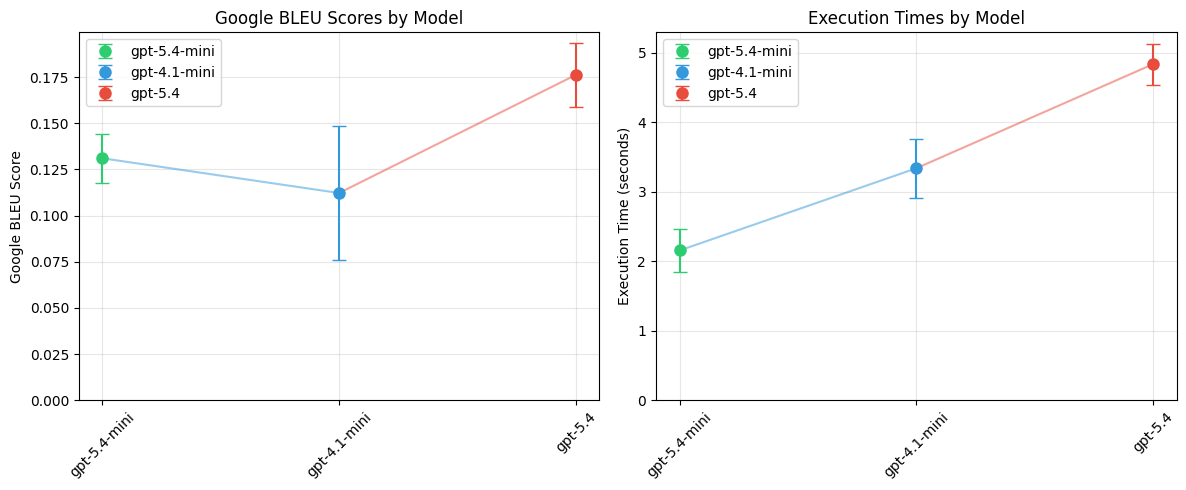

In [ ]:
# モデルごとに統計を計算する
stats = combined_df.groupby('model').agg({
    'feedback.google_bleu': ['mean', 'std'],
    'execution_time': ['mean', 'std']
}).round(4)

# 実行時間でソートする
stats = stats.sort_values(('execution_time', 'mean'))

# 2つのサブプロットを横に並べた図を作成する
import matplotlib.pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# モデルの配色を定義する
colors = ['#2ecc71', '#3498db', '#e74c3c']
models = stats.index

# Google BLEUスコアをプロットする
bleu_means = stats[('feedback.google_bleu', 'mean')]
bleu_stds = stats[('feedback.google_bleu', 'std')]

for i, model in enumerate(models):
    ax1.errorbar(i, bleu_means[model], yerr=bleu_stds[model],
                fmt='o', color=colors[i], markersize=8, capsize=5,
                label=model)
    if i > 0:
        ax1.plot([i-1, i], [bleu_means[models[i-1]], bleu_means[model]],
                 '-', color=colors[i], alpha=0.5)

ax1.set_ylabel('Google BLEU Score')
ax1.set_title('Google BLEU Scores by Model')
ax1.set_xticks(range(len(models)))
ax1.set_xticklabels(models, rotation=45)
ax1.set_ylim(bottom=0)  # Y軸が0から始まるように設定する
ax1.legend()
ax1.grid(True, alpha=0.3)

# 実行時間をプロットする
exec_means = stats[('execution_time', 'mean')]
exec_stds = stats[('execution_time', 'std')]

for i, model in enumerate(models):
    ax2.errorbar(i, exec_means[model], yerr=exec_stds[model],
                fmt='o', color=colors[i], markersize=8, capsize=5,
                label=model)
    if i > 0:
        ax2.plot([i-1, i], [exec_means[models[i-1]], exec_means[model]],
                 '-', color=colors[i], alpha=0.5)

ax2.set_ylabel('Execution Time (seconds)')
ax2.set_title('Execution Times by Model')
ax2.set_xticks(range(len(models)))
ax2.set_xticklabels(models, rotation=45)
ax2.set_ylim(bottom=0)  # Y軸が0から始まるように設定する
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# 統計の表を表示する
print("\nDetailed Statistics:")
stats


Detailed Statistics:


feedback.google_bleu         execution_time        
                             mean     std           mean     std
model                                                           
gpt-5.4-mini               0.1310  0.0132         2.1563  0.3116
gpt-4.1-mini               0.1122  0.0365         3.3391  0.4212
gpt-5.4                    0.1761  0.0172         4.8372  0.2946

In [ ]:
from pydantic import BaseModel
from typing import List, Dict

class JudgeEvaluation(BaseModel):
    expertise: int
    coherence: int
    fluency: int
    similarity: int

def evaluate_with_llm(judge_model: str, candidate_summary: str,
    reference_summary: str) -> Dict[str, float]:
    """
    LLMを使用して、候補要約を参照要約と比較して評価する。

    Args:
        judge_model (str): 評価に使用するモデルの名前
        candidate_summary (str): 評価対象となる生成済みの要約
        reference_summary (str): ベンチマークとなる要約（正解）

    Returns:
        dict: 評価スコアを格納した辞書

    """
    prompt = f"""
    ROLE: You are an expert evaluator of SEC Filing summaries.
    Evaluate the following candidate summary against the reference
    summary on a scale of 1 to 10 for the following criteria:
    - Expertise: Does the summary look like it was written
    by an expert analyst?
    - Coherence: Is the candidate summary logically organized
    and easy to understand?
    - Fluency: Is the language of the candidate summary clear
    and grammatically correct?
    - Similarity: How similar is the candidate summary
    compared to the reference summary?

    Reference Summary:
    "{reference_summary}"

    Candidate Summary:
    "{candidate_summary}"

    Provide scores in this format:
    Expertise: X, Coherence: Y, Fluency: Z, Similarity: W
    """
    completion = oai_client.beta.chat.completions.parse(
        model=judge_model,
        messages=[{"role": "system", "content": prompt}],
        response_format=JudgeEvaluation
    )
    return completion.choices[0].message.parsed

In [ ]:
from langsmith.evaluation import evaluate

def llm_judge_evaluator(run, example):
    """LLM-as-a-Judge用のLangSmithの評価器ラッパー"""
    # モデルが生成した内容
    candidate_summary = run.outputs["summary"]
    # データセットの正解データ
    reference_summary = example.outputs["summary"]

    # evaluate_with_llm関数を使用する
    scores = evaluate_with_llm(
        judge_model="gpt-5.5",
        candidate_summary=candidate_summary,
        reference_summary=reference_summary
    )

    # LangSmithが想定する形式で返す
    return {
        "key": "llm_judge",
        "score": (
            scores.expertise + scores.coherence +
            scores.fluency + scores.similarity
        ) / 4,
        "comment": f"Expertise: {scores.expertise}, "
                     f"Coherence: {scores.coherence}, "
                     f"Fluency: {scores.fluency},"
                     f"Similarity: {scores.similarity}"
    }

# 評価を実行する
results = evaluate(
    generate_summary,
    data=dataset,
    evaluators=[llm_judge_evaluator],
    num_repetitions=5  # 5回ずつ実行する
)

View the evaluation results for experiment: 'ample-rub-100' at:
https://smith.langchain.com/o/9eeb9c6f-c975-4814-8b3e-354fc1f191a6/datasets/a25cf4b8-0828-4401-974d-b10ed070209f/compare?selectedSessions=6e4e44fb-1162-4496-8adf-7c477438bea0




0it [00:00, ?it/s]

In [ ]:
results

,inputs.sec_filing,outputs.summary,error,reference.summary,feedback.llm_judge,execution_time,example_id,id
0,Apple Inc.\n\nForm 10-K\nFor the Fiscal Year E...,Apple Inc.’s 2024 Form 10-K details the compan...,None,Apple’s fiscal 2024 Form 10-K describes the co...,6.75,2.892898,573f37fb-6d4f-4f5e-95cd-75e6cca8b82b,019eb4dc-b63f-76e3-bb5c-cb4675d709db
1,Apple Inc.\n\nForm 10-K\nFor the Fiscal Year E...,Apple Inc.’s 2024 Form 10-K highlights the com...,None,Apple’s fiscal 2024 Form 10-K describes the co...,7.25,2.808489,573f37fb-6d4f-4f5e-95cd-75e6cca8b82b,019eb4dc-cd27-77b3-a989-a02cb96e243f
2,Apple Inc.\n\nForm 10-K\nFor the Fiscal Year E...,Apple Inc.’s 2024 Form 10-K outlines the compa...,None,Apple’s fiscal 2024 Form 10-K describes the co...,7.25,2.459173,573f37fb-6d4f-4f5e-95cd-75e6cca8b82b,019eb4dc-e404-7433-8918-ba9cbc1f2d18
3,Apple Inc.\n\nForm 10-K\nFor the Fiscal Year E...,Apple Inc.’s 2024 Form 10-K highlights the com...,None,Apple’s fiscal 2024 Form 10-K describes the co...,7.00,3.314599,573f37fb-6d4f-4f5e-95cd-75e6cca8b82b,019eb4dc-f803-72e1-8796-b8204c8a29ab
4,Apple Inc.\n\nForm 10-K\nFor the Fiscal Year E...,Apple Inc.’s Form 10-K for fiscal year 2024 ou...,None,Apple’s fiscal 2024 Form 10-K describes the co...,7.00,3.102521,573f37fb-6d4f-4f5e-95cd-75e6cca8b82b,019eb4dd-0fe2-7af0-8641-60dcfc147c10
